# Лабораторна робота №3: класифікатор k-найближчих сусідів (k-NN)

Імпорт бібліотек та завантаження датасету Iris

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
df_iris = pd.read_csv('IrisData_full.csv', header=None, names=columns)

print(f"Розмір датасету: {df_iris.shape}")
df_iris.head()

Розмір датасету: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


Перемішування записів

In [6]:
df_iris = df_iris.sample(frac=1, random_state=8).reset_index(drop=True)

print("Записи успішно перемішано!")
df_iris.head()

Записи успішно перемішано!


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.0,3.6,1.4,0.2,Iris-setosa
1,4.7,3.2,1.6,0.2,Iris-setosa
2,5.2,3.5,1.5,0.2,Iris-setosa
3,6.9,3.1,5.1,2.3,Iris-virginica
4,6.7,3.1,4.4,1.4,Iris-versicolor


Розподіл на матрицю ознак (X) та цільову змінну (y)

In [7]:
target_col = df_iris.columns[-1]
X = df_iris.drop(columns=[target_col])
y = df_iris[target_col]

Розбиття даних на тренувальну та тестову вибірки

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=8, stratify=y
)

print(f"Розмір тренувальних даних: {X_train.shape}")
print(f"Розмір тестових даних: {X_test.shape}")

Розмір тренувальних даних: (105, 4)
Розмір тестових даних: (45, 4)


Нормалізація ознак (MinMaxScaler, діапазон від 0 до 1)

In [9]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Базова модель KNN з K = 5

In [10]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

Оцінка якості базової моделі

In [11]:
y_pred = knn.predict(X_test_scaled)

print(f"Точність (Accuracy): {accuracy_score(y_test, y_pred):.4f}\n")
print("Детальний звіт з класифікації:")
print(classification_report(y_test, y_pred))

Точність (Accuracy): 0.9778

Детальний звіт з класифікації:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       1.00      0.93      0.97        15
 Iris-virginica       0.94      1.00      0.97        15

       accuracy                           0.98        45
      macro avg       0.98      0.98      0.98        45
   weighted avg       0.98      0.98      0.98        45



Перебір різних значень K та пошук найкращого

Найкраще значення K: 2 з точністю: 1.0000


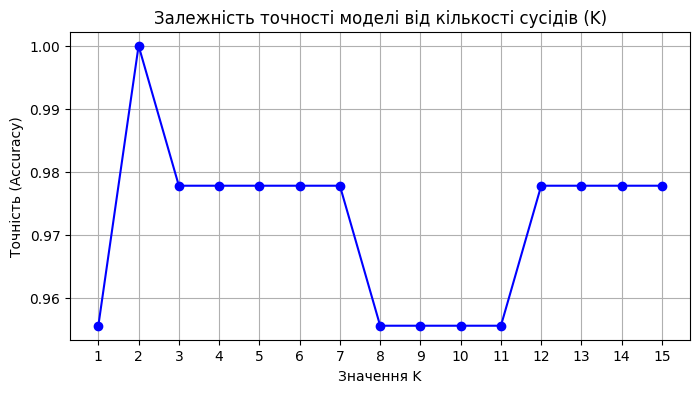

In [12]:
k_values = range(1, 16)
accuracies = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)

    y_pred = knn.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)

best_k = k_values[accuracies.index(max(accuracies))]
print(f"Найкраще значення K: {best_k} з точністю: {max(accuracies):.4f}")

plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='b')
plt.title('Залежність точності моделі від кількості сусідів (K)')
plt.xlabel('Значення K')
plt.ylabel('Точність (Accuracy)')
plt.grid(True)
plt.xticks(k_values)
plt.show()

Підсумкова модель з найкращим K

K = 2, точність (Accuracy): 1.0000

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       1.00      1.00      1.00        15
 Iris-virginica       1.00      1.00      1.00        15

       accuracy                           1.00        45
      macro avg       1.00      1.00      1.00        45
   weighted avg       1.00      1.00      1.00        45



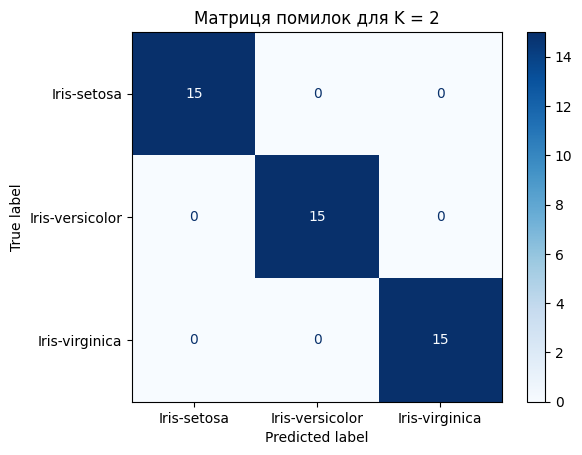

In [13]:
final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(X_train_scaled, y_train)
y_pred_final = final_knn.predict(X_test_scaled)

print(f"K = {best_k}, точність (Accuracy): {accuracy_score(y_test, y_pred_final):.4f}\n")
print(classification_report(y_test, y_pred_final))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_final, cmap='Blues')
plt.title(f'Матриця помилок для K = {best_k}')
plt.show()